# Urban heat at LA28 facilities (draft solution)

**Proposed final project Task 2. Draft solution for the instructor, not student-facing.**

Every code cell starts with a label:

- `📋 PROVIDED TO STUDENTS`: students get this code in the instructions;
- `# 📋 PARTLY PROVIDED`: students get part of the code and fill in the rest;
- `# 💡 HINT IN THE INSTRUCTIONS`: the code appears as a hint in the instructions;
- `✏️ STUDENTS WRITE`: students write it.

Every place students need something we haven't covered in class is marked with 🆕 **Not covered in class:**

Summary of what's new for students:

1. Filtering a STAC search by cloud cover (`query=` parameter). *Provided, with an explanation.*
2. Checking which scenes cover all the facilities (a loop with `within()`). *Provided; students explain the output and use it to pick their scene.*
3. Opening a raster with `masked=True` so no-data values become NaN when the file is loaded. *Hint in the instructions.*
4. Reading the scale and offset from the STAC metadata to convert the raster to degrees Celsius. The file itself doesn't record them, so rioxarray shows the defaults (scale 1, offset 0). *The metadata code is provided; students do the conversion.*
5. Buffering points (`.buffer()`) to turn facility locations into areas.
6. Calculating a statistic per polygon (a loop over facilities with `rio.clip()`). *The one-facility version is a hint in the instructions.*

Everything else (STAC access with `pystac_client`, `open_rasterio` from an asset href, `squeeze`, `clip_box` + `clip`, no-data values, `points_from_xy`, `to_crs`, `contextily`, pandas plotting) was covered in L4: plotting with pandas, L11: CSV to GeoDataFrame, L16: STAC, L17: raster wrangling, and discussion section 8.

## Pipeline

1. Get the LA urban area polygon.
2. Load the LA28 facility locations and compare them with the urban area polygon.
3. Use the urban area polygon to search the Microsoft Planetary Computer for Landsat Collection 2 Level-2 scenes from June to September 2026.
4. Pick a scene based on coverage and cloud cover; retrieve the item and open the surface temperature raster.
5. Convert the raster to °C using the scale and offset; plot it with the facilities and the urban area.
6. Calculate each facility's mean temperature within 500 m and compare it to the urban average.
7. Plot each facility's difference from the urban average.
8. Map the facilities colored by that difference.
9. Discussion questions.

## About

**Event.** NASA JPL's ECOSTRESS team is working with the LA28 Olympics committee on heat mitigation for venues, transportation corridors and pedestrian areas ahead of the 2028 Games. In this task you will make a similar (simpler) analysis with Landsat data: how hot does the ground get around LA28 facilities compared to the Los Angeles urban area as a whole?

**Question.** On a clear late-summer day, which LA28 facilities sit in areas hotter or cooler than the urban area's average, and by how much?

We answer it in **relative** terms: degrees above or below the urban average *on the same date*. Absolute surface temperatures change a lot from one day to the next (see below), but comparisons within one scene are more robust.

**Why Landsat and not ECOSTRESS?** ECOSTRESS is not on the Microsoft Planetary Computer and needs a NASA Earthdata account. Landsat Collection 2 Level-2 includes a surface temperature band and needs no account.

## About the data

1. **Landsat Collection 2 Level-2 surface temperature** (`landsat-c2-l2` collection, `lwir11` asset), from the Microsoft Planetary Computer STAC catalog. Pixels are 30 m, resampled from the thermal sensor's native 100 m.

    **Surface temperature is not air temperature.** Landsat measures the thermal radiation coming off the top millimeter of whatever it sees from above: roofs, pavement, treetops, grass, water. Dark pavement and roofs in full sun often reach 50 to 70 °C, while the air a few feet above them is much cooler. Air temperature (what a weather station reports) is measured in the shade, about 2 m above the ground, and changes much more slowly across a city. Some consequences for this analysis:
    - the satellite sees the top of a roof or a tree canopy, not the shaded sidewalk where people stand;
    - converting radiation to temperature requires assuming how efficiently each surface emits heat (its *emissivity*); this is hard for urban materials such as metal roofs and is a major source of uncertainty, along with the atmospheric correction;
    - dry grass and bare soil get almost as hot as pavement by late summer, while irrigated grass stays cool;
    - surface temperature is a good indicator of where the built environment stores heat (and where shade or vegetation would help), but it is not a direct measure of how hot people feel.

2. **Census 2020 urban areas**, US Census Bureau TIGER/Line 2026 shapefile (`tl_2026_us_uac20`, https://www2.census.gov/geo/tiger/TIGER2026/UAC20/). We use the *Los Angeles--Long Beach--Anaheim, CA* urban area as our reference area: the Census defines urban areas as densely developed territory, so its average temperature represents the city people live in, without the mountains, desert or ocean that a county or city boundary would include.

3. **LA28 facilities** (`la28-facilities.csv`, provided). The 19 **permanent, on-land** LA28 competition facilities in the Los Angeles area, with approximate coordinates. The list comes from the LA28 venue list cross-referenced with Wikipedia's venue statuses. It leaves out:
    - temporary venues (e.g. Venice Beach, Sepulveda Basin, the Long Beach Convention Center lot), since Landsat can only see what is built today;
    - water venues (Port of Los Angeles, Long Beach Marine Stadium, Belmont Pier), since over water Landsat measures the water surface;
    - venues outside the LA area (Trestles, Oklahoma City and the football stadiums in other cities).

## Setup

In [1]:
# ✏️ STUDENTS WRITE
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray as rioxr
import contextily as ctx

from shapely.geometry import shape  # To turn GeoJSON dictionaries into geometries
from pystac_client import Client
import planetary_computer

## 1. Reference area: Los Angeles urban area

The file has every urban area in the US. We keep only Los Angeles.

EPSG:4269
Land area: 4,243 km²
Water area: 46 km²


<Axes: >

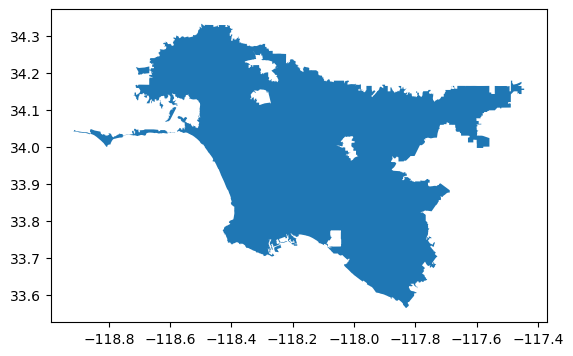

In [2]:
# ✏️ STUDENTS WRITE
urban = gpd.read_file('data/tl_2026_us_uac20/tl_2026_us_uac20.shp')
urban = urban[urban['NAME20'] == 'Los Angeles--Long Beach--Anaheim, CA']

print(urban.crs)
print(f"Land area: {urban['ALAND20'].iloc[0] / 1000**2:,.0f} km²")
print(f"Water area: {urban['AWATER20'].iloc[0] / 1000**2:,.0f} km²")
urban.plot()

## 2. LA28 facilities

We read the CSV and turn it into a geo-data frame, as in L11: CSV to GeoDataFrame.

In [3]:
# ✏️ STUDENTS WRITE
facilities = pd.read_csv('data/la28-facilities.csv')
facilities = gpd.GeoDataFrame(facilities,
                              geometry=gpd.points_from_xy(facilities['lon'], facilities['lat']),
                              crs='epsg:4326')
facilities[['facility', 'city', 'sports']]

,facility,city,sports
0,BMO Stadium,Los Angeles,Flag Football; Lacrosse
1,Crypto.com Arena,Los Angeles,Artistic Gymnastics; Boxing; Trampoline Gymnas...
2,Dignity Health Sports Park,Carson,Archery; Rugby Sevens; Tennis; Wheelchair Tennis
3,Dodger Stadium,Los Angeles,Baseball
4,Fairplex (Knight Riders Cricket Ground),Pomona,Cricket
5,Galen Center,Los Angeles,Badminton; Para Badminton; Rhythmic Gymnastics...
6,Honda Center,Anaheim,Volleyball
7,Intuit Dome,Inglewood,Basketball
8,LA Clays Shooting Sports Park,Whittier Narrows (unincorporated LA County),Shooting
9,Long Beach Arena,Long Beach,Handball; Sitting Volleyball


All 19 facilities are inside the urban area. **We tell students this in the instructions** rather than having them check it.

> **Instructor note:** checking it in code (e.g. `facilities.within(urban_polygon).all()`) is something we might add to the task later.

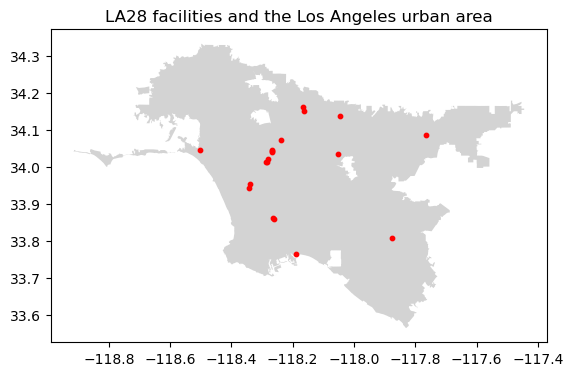

In [4]:
# ✏️ STUDENTS WRITE
fig, ax = plt.subplots()
urban.to_crs(facilities.crs).plot(ax=ax, color='lightgray')
facilities.plot(ax=ax, color='red', markersize=10)
ax.set_title('LA28 facilities and the Los Angeles urban area')
plt.show()

## 3. STAC search: Landsat surface temperature

In [5]:
# ✏️ STUDENTS WRITE
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Bounding box of the urban area in lat/lon, as the search expects
urban_bbox = list(urban.to_crs('epsg:4326').total_bounds)

🆕 **Not covered in class:** filtering a search by item properties. Clouds hide the ground from the thermal sensor, so we only want nearly cloud-free scenes. The `query` parameter filters items by any property in their metadata, here `eo:cloud_cover` (a percentage).

**Provided to students:** the `query=` line and this explanation. Students fill in `collections`, `bbox` and `datetime`.

> **Instructor note:** `query=` uses the older STAC Query extension. The current standard is CQL2, through the `filter=` parameter (e.g. `filter={'op': '<', 'args': [{'property': 'eo:cloud_cover'}, 10]}`). `query=` still works on the Planetary Computer and is simpler to read, so we keep it here.

In [6]:
# 📋 PARTLY PROVIDED: the query line is given; students fill in collections, bbox and datetime
search = catalog.search(
    collections=['landsat-c2-l2'],
    bbox=urban_bbox,
    datetime='2026-06-01/2026-09-30',
    query={'eo:cloud_cover': {'lt': 10}},
)
items = search.item_collection()
len(items)

23

## 4. Pick a scene and open the raster

🆕 **Not covered in class:** checking a scene's coverage. Landsat scenes are tiles, and the LA urban area sits near the corner of one. This code checks which footprints contain all the facilities.

**Provided to students.** They explain what the code does and what its output shows, then use it to pick and justify their scene.

In [7]:
# 📋 PROVIDED TO STUDENTS
facilities_4326 = facilities.to_crs('epsg:4326')

for item in items:
    footprint = shape(item.geometry)
    print(item.id,
          item.properties['eo:cloud_cover'],
          'covers all facilities:', facilities_4326.within(footprint).all())

LC09_L2SP_041036_20260930_02_T1 0.64 covers all facilities: True
LC08_L2SP_042036_20260929_02_T1 0.15 covers all facilities: False
LC09_L2SP_040036_20260923_02_T1 0.02 covers all facilities: False
LC08_L2SP_041036_20260922_02_T1 0.43 covers all facilities: True
LC08_L2SP_040036_20260915_02_T1 0.87 covers all facilities: False
LC09_L2SP_041036_20260914_02_T1 1.62 covers all facilities: True
LC08_L2SP_042036_20260913_02_T1 4.54 covers all facilities: False
LC09_L2SP_042036_20260905_02_T1 0.05 covers all facilities: False
LC08_L2SP_040037_20260830_02_T1 1.44 covers all facilities: False
LC09_L2SP_040036_20260822_02_T1 0.06 covers all facilities: False
LC08_L2SP_041036_20260821_02_T1 0.21 covers all facilities: True
LC08_L2SP_040036_20260814_02_T1 0.08 covers all facilities: False
LC09_L2SP_040036_20260806_02_T1 1.78 covers all facilities: False
LC08_L2SP_041036_20260805_02_T1 8.48 covers all facilities: True
LC08_L2SP_040036_20260729_02_T1 0.0 covers all facilities: False
LC09_L2SP_041036

We pick the scene from **August 21, 2026** (Landsat 8): it covers all facilities and has the lowest cloud cover.

> **Instructor note:** the scene covers about 99% of the urban area. A sliver at the southeastern tip (around Laguna Niguel) is outside it and comes out as no-data. It doesn't affect the facilities and barely changes the urban average.

> **Student decision:** which scene to use. Any clear summer scene that covers all the facilities works. Students say why they picked theirs (coverage, cloud cover, heat wave, time of year).

Two simple ways to get the item out of `items`:

**Option 1: by position.** In the printout above, the Aug 21 scene is the 11th line, so its position is 10 (Python counts from 0). Printing the id afterwards confirms we got the right one.

In [8]:
# ✏️ STUDENTS WRITE
item = items[10]
item.id

'LC08_L2SP_041036_20260821_02_T1'

> **Instructor note:** positions depend on the order the catalog returns the items, so this only works right after the printout. Printing `item.id` is the check.

**Option 2: by id, with a loop.** Go through the items and keep the one whose id matches.

In [9]:
# ✏️ STUDENTS WRITE
for i in items:
    if i.id == 'LC08_L2SP_041036_20260821_02_T1':
        item = i

print(item.id)
print(item.properties['datetime'])

LC08_L2SP_041036_20260821_02_T1
2026-08-21T18:28:05.822606Z


The time is in UTC: 18:28 UTC is **11:28 am** in Los Angeles. Landsat always passes over in the late morning, before the hottest part of the day. ECOSTRESS's map averaged 1 to 4 pm.

In [10]:
# ✏️ STUDENTS WRITE
for key in item.assets.keys():
    print(key, '--', item.assets[key].title)

qa -- Surface Temperature Quality Assessment Band
ang -- Angle Coefficients File
red -- Red Band
blue -- Blue Band
drad -- Downwelled Radiance Band
emis -- Emissivity Band
emsd -- Emissivity Standard Deviation Band
trad -- Thermal Radiance Band
urad -- Upwelled Radiance Band
atran -- Atmospheric Transmittance Band
cdist -- Cloud Distance Band
green -- Green Band
nir08 -- Near Infrared Band 0.8
lwir11 -- Surface Temperature Band
swir16 -- Short-wave Infrared Band 1.6
swir22 -- Short-wave Infrared Band 2.2
coastal -- Coastal/Aerosol Band
mtl.txt -- Product Metadata File (txt)
mtl.xml -- Product Metadata File (xml)
mtl.json -- Product Metadata File (json)
qa_pixel -- Pixel Quality Assessment Band
qa_radsat -- Radiometric Saturation and Terrain Occlusion Quality Assessment Band
qa_aerosol -- Aerosol Quality Assessment Band
tilejson -- TileJSON with default rendering
rendered_preview -- Rendered preview


🆕 **Not covered in class:** `masked=True`. The surface temperature file uses 0 to mark pixels with no data (outside the scene, or where the temperature couldn't be calculated). With `masked=True`, rioxarray turns those pixels into NaN as it loads the file, so they can't sneak into our calculations. Without it, each 0 would become a temperature of -124 °C after the conversion below, and drag every average down.

**Hint in the instructions:** open the raster with `rioxr.open_rasterio(..., masked=True)`.

In [11]:
# ✏️ STUDENTS WRITE
lst = rioxr.open_rasterio(item.assets['lwir11'].href, masked=True)
lst = lst.squeeze('band', drop=True)

print('CRS:', lst.rio.crs)
print('Resolution:', lst.rio.resolution())
print('No-data value:', lst.rio.nodata)
print('Data type:', lst.dtype)
print('Attributes:', lst.attrs)

CRS: EPSG:32611
Resolution: (30.0, -30.0)
No-data value: nan
Data type: float32
Attributes: {'AREA_OR_POINT': 'Point', 'scale_factor': 1.0, 'add_offset': 0.0}


A first look: the raw raster (no scale or unit conversion yet), with the urban area and the facilities. The raster is the whole Landsat scene, so this also shows how much of the urban area it covers.

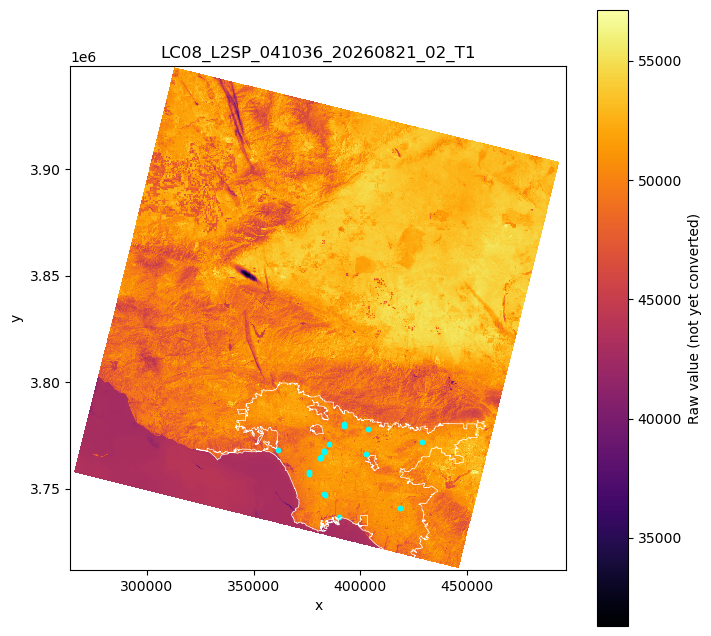

In [12]:
# ✏️ STUDENTS WRITE
fig, ax = plt.subplots(figsize=(8, 8))
lst.plot(ax=ax, cmap='inferno', cbar_kwargs={'label': 'Raw value (not yet converted)'})
urban.to_crs(lst.rio.crs).boundary.plot(ax=ax, color='white', linewidth=0.5)
facilities.to_crs(lst.rio.crs).plot(ax=ax, color='cyan', markersize=10)
ax.set_title(item.id)
plt.show()

## 5. Convert to °C

🆕 **Not covered in class:** scale and offset. The values in the file are integers, not temperatures (`masked=True` turned them into floats so they can hold NaN). To save space, Landsat stores each temperature as an integer, and we have to convert it back with:

$$\text{temperature (K)} = \text{value} \times \text{scale} + \text{offset}$$

The attributes above show `scale_factor: 1.0` and `add_offset: 0.0`. Those are rioxarray's defaults: the file doesn't record how to convert its integers, so a scale of 1 would give values around 47,000 K. The real scale and offset are in the STAC metadata for the asset:

**Provided to students.** They do the conversion to °C themselves.

In [13]:
# 📋 PROVIDED TO STUDENTS
item.assets['lwir11'].extra_fields['raster:bands']

[{'unit': 'kelvin',
  'scale': 0.00341802,
  'nodata': 0,
  'offset': 149,
  'data_type': 'uint16',
  'spatial_resolution': 30}]

### Clip to the urban area

As in L17: raster wrangling. Match the CRS, clip to the bounding box first, then to the polygon.

In [14]:
# ✏️ STUDENTS WRITE
urban = urban.to_crs(lst.rio.crs)
assert urban.crs == lst.rio.crs

lst_urban = lst.rio.clip_box(*urban.total_bounds).rio.clip(urban.geometry)

Now convert to °C. Pixels outside the urban area are already NaN, because the raster was opened with `masked=True`.

In [15]:
# ✏️ STUDENTS WRITE
band = item.assets['lwir11'].extra_fields['raster:bands'][0]

lst_urban = lst_urban * band['scale'] + band['offset'] - 273.15   # integers -> K -> °C

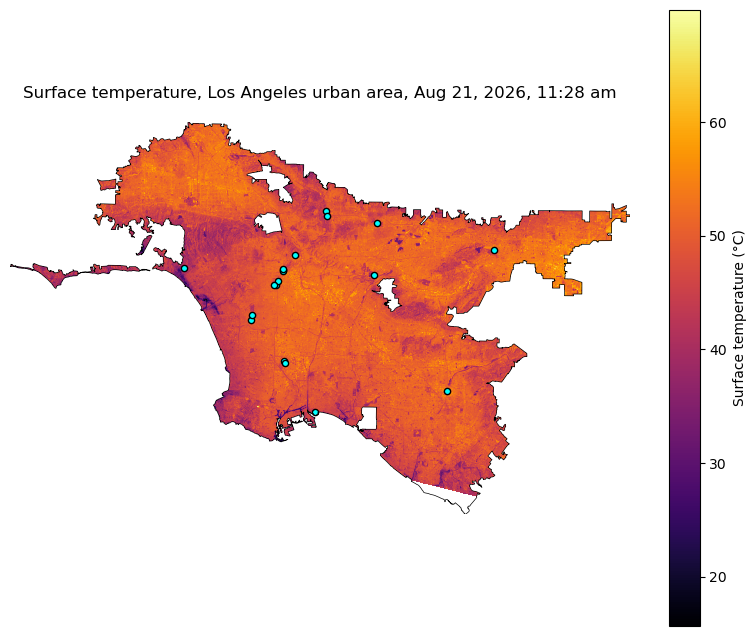

In [16]:
# ✏️ STUDENTS WRITE
facilities = facilities.to_crs(lst_urban.rio.crs)

fig, ax = plt.subplots(figsize=(10, 8))
lst_urban.plot(ax=ax, cmap='inferno', cbar_kwargs={'label': 'Surface temperature (°C)'})
urban.boundary.plot(ax=ax, color='black', linewidth=0.5)
facilities.plot(ax=ax, color='cyan', edgecolor='black', markersize=20)
ax.set_title('Surface temperature, Los Angeles urban area, Aug 21, 2026, 11:28 am')
ax.set_axis_off()
plt.show()

Quick check that the values make sense:

In [17]:
# ✏️ STUDENTS WRITE
print(f"Min: {float(lst_urban.min()):.1f} °C")
print(f"Max: {float(lst_urban.max()):.1f} °C")
print(f"Mean: {float(lst_urban.mean()):.1f} °C")

Min: 15.7 °C
Max: 69.9 °C
Mean: 48.7 °C


> **Data check for students:** surface temperatures of 50+ °C are normal for asphalt and rooftops on a summer day. **This is the temperature of the ground, not of the air.** The hottest pixels (60 to 70 °C, less than 0.1% of the area) are airport runways and large warehouse roofs, e.g. around Ontario Airport and Van Nuys Airport. The coolest pixels are water the urban area still includes (reservoirs, harbor channels) and irrigated green spaces.

> **Instructor note: absolute values depend on the date.** Urban-area mean surface temperature on the other clear 2026 scenes I checked: Jun 10: 46.1 °C, Aug 5: 42.4 °C, **Aug 21: 48.7 °C**, Sep 14: 40.1 °C, Sep 22: 38.3 °C. This is why we report results relative to the urban average on the same date.

## 6. Statistics: facilities vs. the urban area

🆕 **Not covered in class:** buffering. A facility is a point, but we want the temperature of the area around it. `.buffer(500)` draws a circle with a 500 m radius around each point.

The buffer distance is in the units of the CRS, so the facilities must be in a projected CRS in meters. Buffering in EPSG:4326 would give a radius of 500 *degrees*. The facilities are already in the raster's CRS, UTM zone 11N (EPSG:32611), which is in meters.

> **Instructor note:** no hint for this step; projecting before buffering has been discussed extensively in class. When grading, watch for buffers made in EPSG:4326 (a 500-*degree* radius). GeoPandas only warns about it, so the code runs and the problem shows up later, as a clipping error or as meaningless values.

In [18]:
# ✏️ STUDENTS WRITE
facilities['geometry'] = facilities.buffer(500)

> **Instructor note:** in downtown LA, Crypto.com Arena, Peacock Theater and the LA Convention Center are 200 to 400 m apart, so their 500 m buffers overlap almost completely and give nearly the same numbers. Good material for the "limitations of the methods" question.

The urban area's average is our reference:

In [19]:
# ✏️ STUDENTS WRITE
urban_mean = float(lst_urban.mean())
urban_mean

48.65544891357422

🆕 **Not covered in class:** statistics per polygon. We clip the temperature raster to each facility's buffer, one at a time. Every facility is inside the urban area, so we can clip `lst_urban` directly.

**Hint in the instructions:** do it for one facility first, then put the same steps in a loop.

In [20]:
# 💡 HINT IN THE INSTRUCTIONS
# One facility first: the first row is BMO Stadium
geom = facilities.geometry.iloc[0]
facility_lst = lst_urban.rio.clip([geom])   # clip() expects a list of geometries

print(facilities['facility'].iloc[0])
print(float(facility_lst.mean()) - urban_mean)

BMO Stadium
-0.47457122802734375


Now the same steps for every facility:

In [21]:
# ✏️ STUDENTS WRITE
mean_temps = []

for geom in facilities.geometry:
    facility_lst = lst_urban.rio.clip([geom])
    mean_temps.append(float(facility_lst.mean()))

facilities['mean_temp_c'] = mean_temps

# Relative result: difference from the urban average
facilities['diff_from_urban_c'] = facilities['mean_temp_c'] - urban_mean

results = (facilities[['facility', 'city', 'diff_from_urban_c']]
           .sort_values('diff_from_urban_c', ascending=False)
           .round(1))
results

,facility,city,diff_from_urban_c
4,Fairplex (Knight Riders Cricket Ground),Pomona,3.5
6,Honda Center,Anaheim,2.6
16,Santa Anita Park,Arcadia,2.6
3,Dodger Stadium,Los Angeles,1.5
18,VELO Sports Center,Carson,1.1
10,Los Angeles Convention Center,Los Angeles,0.9
1,Crypto.com Arena,Los Angeles,0.4
12,Peacock Theater,Los Angeles,-0.0
5,Galen Center,Los Angeles,-0.1
2,Dignity Health Sports Park,Carson,-0.2


Each 500 m buffer covers about 870 Landsat pixels, but the thermal sensor's real resolution is 100 m, so each buffer holds only about 80 independent measurements.

## 7. Difference from the urban average

We plot each facility's difference from the urban average. Positive means hotter than the urban area.

**Provided to students.** They adapt it to their results (e.g. the date and time in the title).

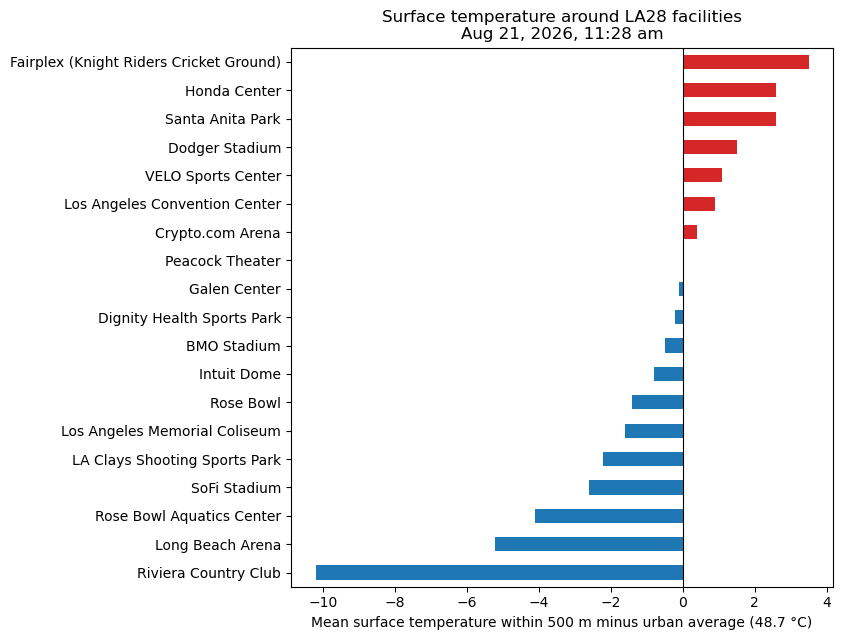

In [22]:
# 📋 PROVIDED TO STUDENTS
plot_data = results.set_index('facility').sort_values('diff_from_urban_c')
colors = ['tab:red' if d > 0 else 'tab:blue' for d in plot_data['diff_from_urban_c']]

ax = plot_data['diff_from_urban_c'].plot.barh(figsize=(7, 7), color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel(f'Mean surface temperature within 500 m minus urban average ({urban_mean:.1f} °C)')
ax.set_ylabel('')
ax.set_title('Surface temperature around LA28 facilities\nAug 21, 2026, 11:28 am')
plt.show()

## 8. Map

Facilities colored by their difference from the urban average, over satellite imagery (contextily, as in discussion section 8).

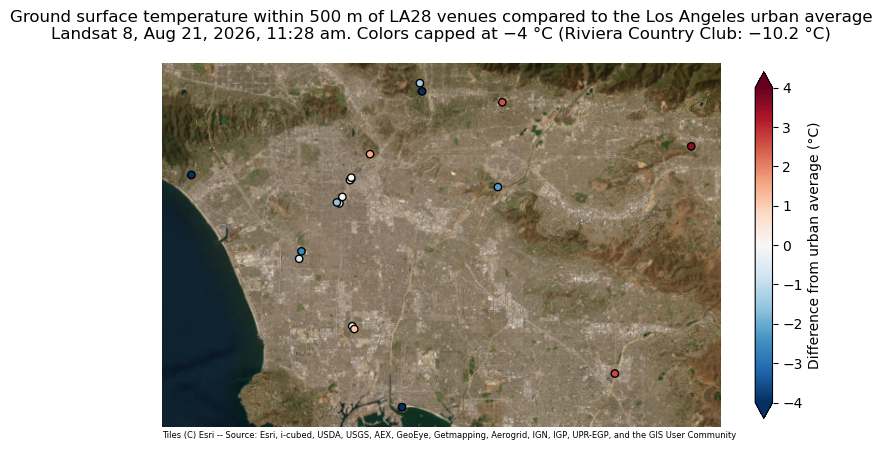

In [23]:
# ✏️ STUDENTS WRITE
fig, ax = plt.subplots(figsize=(9, 9))
limit = 4   # °C, covers every venue except Riviera

facilities.plot(ax=ax,
                column='diff_from_urban_c',
                cmap='RdBu_r',
                vmin=-limit, vmax=limit,
                edgecolor='black',
                legend=True,
                legend_kwds={'label': 'Difference from urban average (°C)',
                             'shrink': 0.5,
                             'extend': 'both'})   # arrow ends: values beyond the limits
ctx.add_basemap(ax, crs=facilities.crs, source=ctx.providers.Esri.WorldImagery, attribution=False)

ax.set_title('Ground surface temperature within 500 m of LA28 venues compared to the Los Angeles urban average\n'
             'Landsat 8, Aug 21, 2026, 11:28 am. Colors capped at −4 °C '
             '(Riviera Country Club: −10.2 °C)',
             fontsize=12)

# Credit text, placed just below the map
basemap = ctx.providers.Esri.WorldImagery
ax.text(0, -0.01, basemap.attribution,
        transform=ax.transAxes,   # coordinates relative to the map: (0, 0) is its bottom-left corner
        fontsize=6, va='top')
ax.set_axis_off()
plt.show()

## 9. Discussion questions

1. Which scene (date) did you use? Which facilities have the minimum and maximum difference from the urban average, and what are these values?
2. Explain two limitations of the data.
3. Explain two limitations of the methods.
4. Discuss your results in relation to the facilities' locations and the type of facility (and any other characteristics you think matter).
5. LA28 is planning heat mitigation for the Games. Based on your map, which venue would you prioritize for heat mitigation, and what would you need to know beyond this analysis to make that recommendation?

### Notes for the answer key

**Question 1.** A quick check that the pipeline is right. Expected values for each of the seven scenes that cover all the facilities (June 1 to September 30, 2026, cloud cover under 10%; 500 m buffers):

| Date | Satellite | Cloud cover (%) | Urban mean (°C) | Maximum difference | Minimum difference |
|---|---|---|---|---|---|
| Jun 10, 2026 | Landsat 9 | 1.89 | 46.1 | Fairplex (Knight Riders Cricket Ground), +2.9 °C | Riviera Country Club, −10.3 °C |
| Jul 28, 2026 | Landsat 9 | 6.44 | 45.1 | Honda Center, +3.3 °C | Riviera Country Club, −10.1 °C |
| Aug 5, 2026 | Landsat 8 | 8.48 | 42.4 | Fairplex (Knight Riders Cricket Ground), +5.2 °C | Riviera Country Club, −7.0 °C |
| **Aug 21, 2026** | Landsat 8 | 0.21 | 48.7 | Fairplex (Knight Riders Cricket Ground), +3.5 °C | Riviera Country Club, −10.2 °C |
| Sep 14, 2026 | Landsat 9 | 1.62 | 40.1 | Honda Center, +4.8 °C | Riviera Country Club, −5.9 °C |
| Sep 22, 2026 | Landsat 8 | 0.43 | 38.3 | Honda Center, +3.3 °C | Riviera Country Club, −6.6 °C |
| Sep 30, 2026 | Landsat 9 | 0.64 | 39.8 | Honda Center, +3.0 °C | Riviera Country Club, −5.6 °C |

Riviera Country Club is the coolest on every date, and the hottest is always Fairplex or Honda Center: the extremes hold even though the values change. The Aug 5 and Jul 28 scenes have the most clouds; cloud pixels read cold, so their values may be less reliable. Small differences (±0.1 °C) can come from package versions.

**Question 2, data.** Possible answers:
- Surface temperature is not air temperature: the satellite sees roofs, pavement and treetops, not the shaded sidewalk where people stand.
- Emissivity and the atmospheric correction are major sources of uncertainty; a typical pixel's absolute temperature is uncertain by about ±2 °C (the `qa` asset). Strong answers note that differences within one scene are more reliable than absolute values, because errors that affect the whole scene the same way cancel out, and averaging many pixels reduces random errors.
- One overpass at about 11:30 am, before the hottest part of the day; the ranking could change in the afternoon (ECOSTRESS averaged 1 to 4 pm).
- One date: absolute values change a lot from scene to scene.
- The thermal sensor's real resolution is 100 m, resampled to 30 m, so a 500 m buffer holds only about 80 independent measurements.
- The facility coordinates are approximate.

**Question 3, methods.** Possible answers:
- A 500 m circle is arbitrary and doesn't follow the facility's footprint; it mixes the venue with its neighborhood.
- Buffers overlap downtown (Crypto.com Arena, Peacock Theater, LA Convention Center), so those facilities aren't measured separately.
- The urban average is one number for a huge area that spans the coast and inland valleys; comparing to a regional or nearby average could change the picture.
- A single scene rather than an average over several clear days.
- The mean hides variation within the buffer (e.g. a cool field next to a hot parking lot).

**Question 4, results.** The hottest facilities (Fairplex, Honda Center, Santa Anita) are inland; the coolest are near the coast or on irrigated grass (Riviera Country Club). Strong answers ask whether the difference is about the facilities themselves (parking lots, roofs, grass) or about where they are (distance to the coast), and how they could tell.

**Question 5, mitigation.** Any well-argued choice. Things to know beyond this analysis: air temperature and humidity (heat index), the time of day and length of events, the number of spectators and how long they stay outside, shade and cooling available, how people get to the venue (walking from transit or parking), and whether the event is indoors.